In [9]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model 
from langchain_tavily import TavilySearch # web search
from langchain.agents import create_agent 
load_dotenv()  # Load environment variables from .env file

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")

llmGPT = init_chat_model("gpt-4.1") # initialize a chat model with the name "gpt-4"
tavilyTool = TavilySearch(max_results=2)

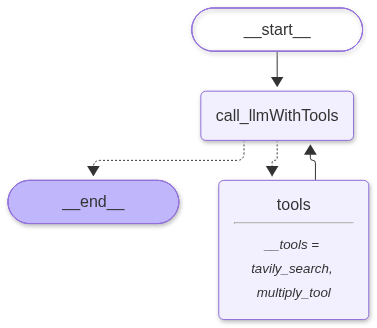

In [ ]:
#StateGraph
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition #langraph has a prebuilt node specifaclly for tools

#state
class State(TypedDict):
    messages: Annotated[list, add_messages]


def multiply_tool(a: int, b: int) -> int: 
    """The tool multiples the value of a(int) and b (int) and retuns the output as an int"""
    return a * b


#tools
tools = [tavilyTool, multiply_tool] #we can add all the tools we have got in this list, and then use the bind_tools method to bind them
llm_with_tools = llmGPT.bind_tools(tools) 

def tool_callingllm(state: State):
    return {"messages" : [llm_with_tools.invoke(state["messages"])]}


#graphs initilazions
graph_builder = StateGraph(State)
graph_builder.add_node("call_llmWithTools", tool_callingllm)

#we cannot name tools, wtv we want here, as when we create graph_builder.add_conditional_edges("call_llmWithTools", tools_condition) 
# tools_condition returns the actual target name of the list which is "tools" so we have to name it same here.
graph_builder.add_node("tools", ToolNode(tools)) 

# Add the Edges, while following the ReACT Formula, Check Images
graph_builder.add_edge(START, "call_llmWithTools")

# if the latest message(result) from the AI assitant is a tool call -> tool_conditon routes to tools
# if the latest message(result) from the AI assitant is not a tool call -> tool_conditon routes to END
graph_builder.add_conditional_edges("call_llmWithTools", tools_condition)
graph_builder.add_edge("tools", "call_llmWithTools") 
graph_builder.add_edge("call_llmWithTools", END) 


#compile the graph
graph = graph_builder.compile()
graph

In [40]:

response = graph.invoke({"messages" : "What is the Weather of Vamcouver right now after that add 5 * 2?"}) # it calls both the tools

#To get staright to the response uncomment:
# message = response["messages"][-1].content
# message

# We can see the Calls and Messages
message = response["messages"]

for m in message:
    m.pretty_print()

================================ Human Message =================================

What is the Weather of Vamcouver right now after that add 5 * 2?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_tdqILW8ftYNRgvvIvmSWdLuv)
 Call ID: call_tdqILW8ftYNRgvvIvmSWdLuv
  Args:
    query: current weather in Vancouver
  multiply_tool (call_hOGsIjTU2SPB52T9IIgoF5UR)
 Call ID: call_hOGsIjTU2SPB52T9IIgoF5UR
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: tavily_search

{"query": "current weather in Vancouver", "follow_up_questions": null, "answer": null, "images": [], "results": [{"title": "Weather in Vancouver", "url": "https://www.weatherapi.com/", "content": "{'location': {'name': 'Vancouver', 'region': 'British Columbia', 'country': 'Canada', 'lat': 49.25, 'lon': -123.1333, 'tz_id': 'America/Vancouver', 'localtime_epoch': 1793953657, 'localtime': '2026-11-06 01:27'}